# Ritmeva modeli gerçek veride: CDNOW

*English summary: the BG/NBD code in `analitik/` is fitted to the public CDNOW sample and reproduces the parameters
published by Fader, Hardie & Lee (2005) to three decimals. Same check runs in CI: `tests/test_cdnow_gercek_veri.py`.*

Ritmeva'nın modeli şimdiye kadar yalnızca bilgisayarla üretilmiş (sentetik) veride sınanmıştı. Bu defterde modeli
**gerçek bir veri setine** uyguluyoruz: CDNOW adlı internet mağazasından 1997-1998'de CD alan 2.357 gerçek müşteri.

Bu veri seçildi çünkü BG/NBD modelini bulan makale (Fader, Hardie & Lee, 2005) tam olarak bu veriyi kullandı ve
sonuçlarını yayımladı. Yani elimizde bir **cevap anahtarı** var: kodum makaledeki sayıları buluyorsa, modeli doğru
yazmışım demektir.

Kullanılanlar: **pandas** (tablo işleri), **NumPy** (hesap), **SciPy** (optimizasyon ve özel fonksiyonlar),
**matplotlib** (grafik). Kurulum: `pip install pandas matplotlib jupyter` (NumPy ve SciPy projede zaten var).

In [1]:
import sys
sys.path.insert(0, "..")          # proje kökü: analitik/ paketini buradan alıyoruz

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import hyp2f1
from scipy.stats import mannwhitneyu

from analitik import bgnbd, mbgnbd
from analitik.bgnbd import BGNBDParametreleri

## 1. Veriyi pandas ile okumak

Her satır bir alışveriş: müşteri numarası (`id`), tarih, kaç CD aldığı ve ödediği para.
Kaynak: Bruce Hardie'nin veri sayfası; buradaki kopya pymc-marketing deposundan.

In [2]:
URL = "https://raw.githubusercontent.com/pymc-labs/pymc-marketing/main/data/cdnow_transactions.csv"
satis = pd.read_csv(URL, dtype={"date": str})
satis["date"] = pd.to_datetime(satis["date"], format="%Y%m%d")
print(satis.shape, "satır/sütun ·", satis["id"].nunique(), "müşteri ·", satis["date"].min().date(), "→", satis["date"].max().date())
satis.head()

(6919, 5) satır/sütun · 2357 müşteri · 1997-01-01 → 1998-06-30


,_id,id,date,cds_bought,spent
0,4,1,1997-01-01,2,29.33
1,4,1,1997-01-18,2,29.73
2,4,1,1997-08-02,1,14.96
3,4,1,1997-12-12,2,26.48
4,21,2,1997-01-01,3,63.34


## 2. Aynı gün yapılan alışverişleri birleştirmek

Bir müşteri aynı gün iki sipariş verdiyse bunu tek "ziyaret" sayıyoruz (stüdyoda da aynı gün iki kez giriş
tek ziyarettir). `groupby` ile müşteri + tarih bazında topluyoruz.

In [3]:
ziyaret = satis.groupby(["id", "date"], as_index=False)["spent"].sum()
print(len(satis), "satış →", len(ziyaret), "ziyaret")

6919 satış → 6696 ziyaret


## 3. Her müşteriyi üç sayıya indirmek

Model her müşteriden yalnızca üç sayı ister:

- **x**: ilk ziyaretten sonra kaç kez daha geldi (tekrar ziyaret sayısı)
- **t_x**: son ziyareti, ilk ziyaretinden kaç gün sonraydı
- **T**: ilk ziyaretinden gözlemin sonuna kadar kaç gün geçti

Örnek: Ali 1 Ocak'ta ilk kez geldi, sonra 2 kez daha geldi, sonuncusu 1 Mart'ta. Gözlem 30 Eylül'de bitiyorsa
x = 2, t_x = 59, T = 272. Makaledeki gibi **ilk 39 haftayı** (30 Eylül 1997'ye kadar) modele veriyoruz, sonraki
39 haftayı modelden saklayıp tahminleri onunla sınayacağız.

In [4]:
KALIBRASYON_SONU = pd.Timestamp("1997-09-30")
BEKLEME_SONU = pd.Timestamp("1998-06-30")          # sonraki 273 gün (39 hafta)

once = ziyaret[ziyaret["date"] <= KALIBRASYON_SONU]
g = once.groupby("id")["date"].agg(["min", "max", "count"])
ozet = pd.DataFrame({
    "x": g["count"] - 1,
    "t_x": (g["max"] - g["min"]).dt.days,
    "T": (KALIBRASYON_SONU - g["min"]).dt.days,
})
sonra = ziyaret[(ziyaret["date"] > KALIBRASYON_SONU) & (ziyaret["date"] <= BEKLEME_SONU)]
ozet["x_bekleme"] = sonra.groupby("id").size().reindex(ozet.index, fill_value=0)

print("Toplam tekrar ziyaret (makalede 2457):", ozet["x"].sum())
print("Hiç tekrar gelmeyenlerin payı:", round((ozet["x"] == 0).mean(), 3))
ozet.head()

Toplam tekrar ziyaret (makalede 2457): 2457
Hiç tekrar gelmeyenlerin payı: 0.599


,x,t_x,T,x_bekleme
id,,,,
1,2,213,272,1
2,1,12,272,0
3,0,0,272,0
4,0,0,272,0
5,0,0,272,0


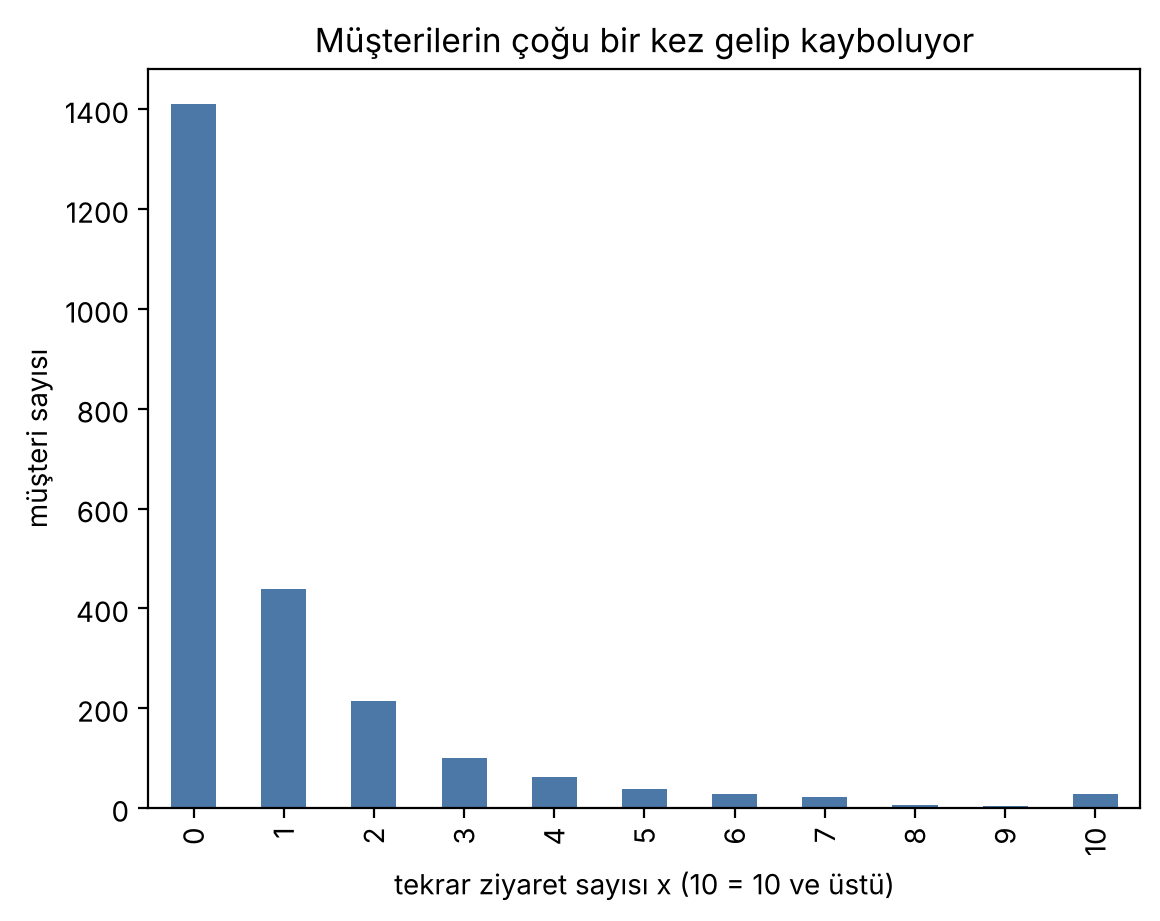

In [5]:
ozet["x"].clip(upper=10).value_counts().sort_index().plot.bar(color="#4c78a8")
plt.xlabel("tekrar ziyaret sayısı x (10 = 10 ve üstü)")
plt.ylabel("müşteri sayısı")
plt.title("Müşterilerin çoğu bir kez gelip kayboluyor")
plt.show()

## 4. Modeli uydurmak ve makaleyle karşılaştırmak

BG/NBD'nin dört parametresi var: gelme hızının dağılımı için **r, α** (Gamma) ve bırakma olasılığının dağılımı için
**a, b** (Beta). Bunları, verinin olabilirliğini en büyük yapan değerler olarak buluyoruz (en çok olabilirlik, MLE).
Olabilirlik fonksiyonu Ritmeva'nın kendi kodu: `analitik.bgnbd.log_olabilirlik`.

Makale zamanı **hafta** ile ölçüyor; karşılaştırma için günleri 7'ye bölüyoruz.

In [6]:
x = ozet["x"].to_numpy(float)
t_x = ozet["t_x"].to_numpy(float)
T = ozet["T"].to_numpy(float)

def mle_hafta(log_olabilirlik):
    def amac(teta):
        deger = -log_olabilirlik(bgnbd.tetadan_parametre(teta), x, t_x / 7, T / 7)
        return deger if np.isfinite(deger) else 1e300
    bas = bgnbd.parametreden_teta(BGNBDParametreleri(r=1.0, alfa=30 / 7, a=1.0, b=1.0))
    s = minimize(amac, bas, method="Nelder-Mead", options={"xatol": 1e-10, "fatol": 1e-10, "maxiter": 40_000})
    return bgnbd.tetadan_parametre(s.x), -s.fun

prm, ll = mle_hafta(bgnbd.log_olabilirlik)
pd.DataFrame({
    "Makale (2005)": [0.243, 4.414, 0.793, 2.426, -9582.4],
    "Ritmeva kodu": [prm.r, prm.alfa, prm.a, prm.b, ll],
}, index=["r", "α (hafta)", "a", "b", "log-olabilirlik"]).round(3)

,Makale (2005),Ritmeva kodu
r,0.243,0.243
α (hafta),4.414,4.414
a,0.793,0.793
b,2.426,2.426
log-olabilirlik,-9582.400,-9582.429


**Dört parametre makaleyle virgülden sonra üç basamağa kadar aynı; log-olabilirlik de makalenin verdiği −9582,4 (makale tek ondalık veriyor).** Kod doğru.

Ritmeva üretimde düz MLE değil, zayıf bir önselle **MAP** kullanıyor (küçük stüdyolarda parametreler kararsız
kaldığı için). 2.357 müşteride bu önsel sonucu ne kadar kaydırıyor?

In [7]:
map_bg = bgnbd.fit(x, t_x, T)          # Ritmeva'nın üretimdeki uyumu (zaman birimi gün)
map_mbg = mbgnbd.fit(x, t_x, T)
pd.DataFrame({
    "MLE (makale)": [0.243, 4.414, 0.793, 2.426],
    "Ritmeva MAP, BG/NBD": [map_bg.r, map_bg.alfa / 7, map_bg.a, map_bg.b],
    "Ritmeva MAP, MBG/NBD": [map_mbg.r, map_mbg.alfa / 7, map_mbg.a, map_mbg.b],
}, index=["r", "α (hafta)", "a", "b"]).round(3)

,MLE (makale),"Ritmeva MAP, BG/NBD","Ritmeva MAP, MBG/NBD"
r,0.243,0.243,0.532
α (hafta),4.414,4.433,6.238
a,0.793,0.806,0.890
b,2.426,2.481,1.591


Önsel BG/NBD parametrelerini en fazla %2-3 oynatıyor: veri büyüyünce önselin etkisi kayboluyor, beklendiği gibi.
MBG/NBD'nin parametreleri farklı çünkü model farklı (ilk ziyaretten sonra da bırakmaya izin veriyor).

## 5. "Bu müşteri hâlâ bizimle mi?"

Aynı sayıda (x = 2) tekrar ziyareti olan üç müşteri düşünelim; tek fark son ziyaretin ne zaman olduğu.

In [8]:
ornek_tx = np.array([260.0, 150.0, 30.0])          # son ziyaret: ilk ziyaretten 260, 150, 30 gün sonra
p = bgnbd.p_hayatta(map_bg, np.full(3, 2.0), ornek_tx, np.full(3, 272.0))
pd.DataFrame({"son ziyaretten beri geçen gün": 272 - ornek_tx, "P(hâlâ müşteri)": p.round(2)})

,son ziyaretten beri geçen gün,P(hâlâ müşteri)
0,12.0,0.80
1,122.0,0.58
2,242.0,0.11


Uzun süredir gelmeyen müşterinin "hâlâ müşteri" olasılığı düşüyor. Ritmeva'nın "neden riskli?" cümlesi bu
hesaptan çıkıyor.

## 6. Saklanan 39 haftayı tahmin etmek

Model yalnızca ilk 39 haftayı gördü. Şimdi sonraki 39 haftada **toplam kaç tekrar ziyaret** olacağını tahmin
ediyoruz. Bir müşterinin ilk ziyaretinden t hafta sonra beklenen tekrar ziyaret sayısı (makale, denklem 9):

$$E[X(t)] = \frac{a+b-1}{a-1}\left[1 - \left(\frac{\alpha}{\alpha+t}\right)^r {}_2F_1\!\left(r, b; a+b-1; \frac{t}{\alpha+t}\right)\right]$$

$_2F_1$ hipergeometrik fonksiyon; SciPy'da `hyp2f1`. Her müşteri için bunu kendi ilk ziyaret gününden başlatıp
topluyoruz.

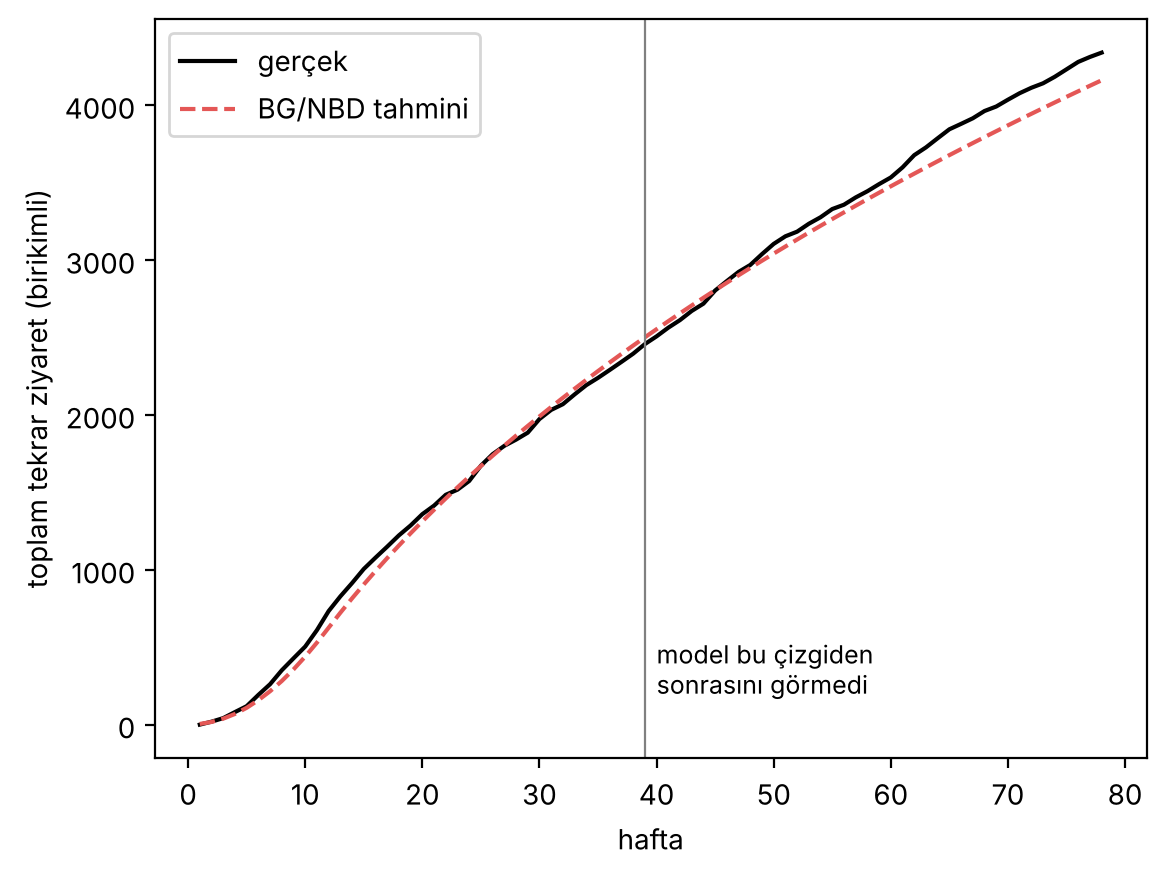

78. hafta: gerçek 4339 · tahmin 4160


In [9]:
def beklenen_tekrar(prm, t):
    t = np.maximum(t, 0)
    r, al, a, b = prm.r, prm.alfa, prm.a, prm.b
    return (a + b - 1) / (a - 1) * (1 - (al / (al + t)) ** r * hyp2f1(r, b, a + b - 1, t / (al + t)))

ilk = g["min"]
haftalar = np.arange(1, 79)
gun_sonu = pd.Timestamp("1997-01-01") + pd.to_timedelta(haftalar * 7 - 1, unit="D")
ilk_gun = (ilk - pd.Timestamp("1997-01-01")).dt.days.to_numpy()
tahmin = [beklenen_tekrar(map_bg, h * 7 - ilk_gun).sum() for h in haftalar]

tekrar = ziyaret.merge(ilk.rename("ilk"), left_on="id", right_index=True)
tekrar = tekrar[tekrar["date"] > tekrar["ilk"]]
gercek = [(tekrar["date"] <= s).sum() for s in gun_sonu]

plt.plot(haftalar, gercek, label="gerçek", color="black")
plt.plot(haftalar, tahmin, "--", label="BG/NBD tahmini", color="#e45756")
plt.axvline(39, color="gray", lw=0.8)
plt.text(40, 200, "model bu çizgiden\nsonrasını görmedi", fontsize=9)
plt.xlabel("hafta"); plt.ylabel("toplam tekrar ziyaret (birikimli)")
plt.legend(); plt.show()
print("78. hafta: gerçek", gercek[-1], "· tahmin", round(tahmin[-1]))

## 7. Dürüst kısım: sıralama başarısı

Ritmeva'nın listesi "en riskliden başla" diyor. Bu yüzden bir de şunu soruyoruz: model, saklanan dönemde **tekrar
gelecek** müşterileri gelmeyecek olanlardan ne kadar iyi ayırıyor? Ölçü ROC AUC (0,5 yazı-tura, 1 kusursuz).
Karşılaştırma: tek bir basit kural, "son ziyaretten beri ne kadar az gün geçtiyse o kadar iyi".

In [10]:
y = ozet["x_bekleme"].to_numpy() > 0
def auc(skor):
    return mannwhitneyu(skor[y], skor[~y]).statistic / (y.sum() * (~y).sum())

t_bekleme = (BEKLEME_SONU - KALIBRASYON_SONU).days
pd.Series({
    "BG/NBD (beklenen ziyaret)": auc(bgnbd.beklenen_ziyaret(map_bg, t_bekleme, x, t_x, T)),
    "MBG/NBD (beklenen ziyaret)": auc(mbgnbd.beklenen_ziyaret(map_mbg, t_bekleme, x, t_x, T)),
    "Basit kural (yakınlık)": auc(-(T - t_x)),
}, name="ROC AUC").round(3)

BG/NBD (beklenen ziyaret)     0.773
MBG/NBD (beklenen ziyaret)    0.773
Basit kural (yakınlık)        0.771
Name: ROC AUC, dtype: float64

**Sonuç:** Bu veride model, sıralamada basit "en son kim geldi" kuralını neredeyse hiç geçemiyor. Modelin asıl
farkı sıralamada değil, **sayı vermesinde**: "bu müşteri önümüzdeki 39 haftada ortalama 0,8 kez gelir" ya da
"risk altındaki para şu kadar" gibi, kuralın veremeyeceği ölçekli tahminler. Ritmeva'daki Riskteki Para da bu
yüzden modelden geliyor.

Sınırlar:
- CDNOW bir CD mağazası, stüdyo değil; paket ve yenileme yok. Bu defter **kodun matematiğini** doğruluyor,
  stüdyodaki yenileme tahminini değil. O ölçüm ilk gerçek stüdyo pilotunda yapılacak (`docs/entegrasyon.md`).
- Birikimli tahmin, saklanan dönemde gerçeğin biraz altında kalıyor; makalenin kendi grafiğinde de model ikinci
  yılda hafifçe düşük tahmin ediyor.

Kaynak: Fader, P. S., Hardie, B. G. S. & Lee, K. L. (2005). "Counting Your Customers" the Easy Way: An
Alternative to the Pareto/NBD Model. *Marketing Science* 24(2), 275-284.